# 03 — Exploratory Data Analysis

## tl;dr

This notebook examines overall demand, stores, product families, promotions, holidays, transactions, and oil prices. It prioritizes interpretable patterns and operational relevance. All relationships are descriptive; promotion, holiday, transaction, and oil comparisons are not causal estimates.

## Context & Methods

High-level analysis uses the full sales panel. Detailed store-family views use the justified subset selected in Notebook 02. Daily averages are preferred when month length or partial periods could distort totals.

### Key assumptions

- Sales aggregate mixed unit types across product families, so portfolio-level totals are an index of activity rather than a common physical unit.
- Promotion comparisons are exposed to selection bias because promotions are not randomly assigned.
- Sales per transaction is a descriptive basket proxy, not revenue or margin per customer.

In [1]:
from pathlib import Path
import sys
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
# Resolve the repository root dynamically so the notebook works from either
# the project root or the notebooks directory without a local absolute path.
candidate = Path.cwd().resolve()
PROJECT_ROOT = next(
    path for path in (candidate, *candidate.parents)
    if (path / "data").is_dir() and (path / "src").is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DATA_DIR = PROJECT_ROOT / "outputs" / "processed_data"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"
for directory in (PROCESSED_DATA_DIR, OUTPUT_DATA_DIR, FIGURE_DIR, TABLE_DIR):
    # Creating output folders is safe; raw source files are never modified.
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src.data_loader import load_all_available
from src.preprocessing import build_analysis_panel
from src.eda import (
    classify_demand_patterns,
    analyze_payday_effects,
    analyze_earthquake_impact,
    compute_cross_family_correlations,
    analyze_promotion_elasticity,
)
from src.visualization import (
    PROJECT_COLORS,
    save_figure,
    set_project_style,
    plot_demand_classification,
    plot_payday_comparison,
    plot_earthquake_impact,
    plot_correlation_heatmap,
)

set_project_style()
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
datasets = load_all_available(RAW_DATA_DIR)
panel = build_analysis_panel(datasets)
scope = json.loads((OUTPUT_DATA_DIR / "analysis_scope.json").read_text())
selected_stores = scope["selected_stores"]
selected_families = scope["selected_families"]

## Results

### 1. Overall demand trend and rolling average

**Why this step is needed:** The network trend establishes the broad direction of observed sales, while a rolling average reduces day-to-day noise so sustained changes are easier to see.

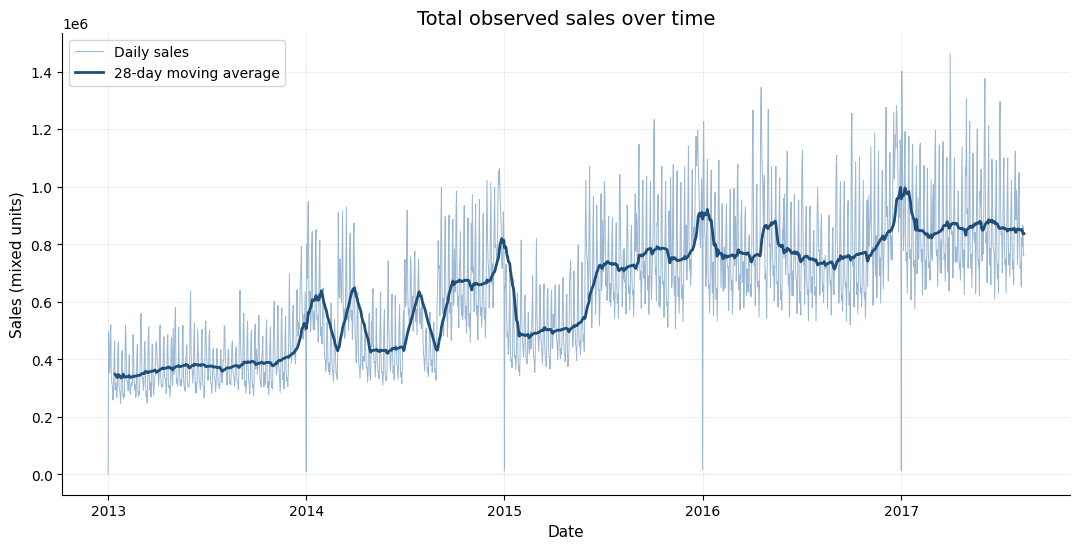

In [3]:
daily_total = panel.groupby("date", observed=True)["sales"].sum().sort_index()
rolling_28 = daily_total.rolling(28, min_periods=14).mean()
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(daily_total.index, daily_total, color="#9bb7d3", linewidth=.7, label="Daily sales")
ax.plot(rolling_28.index, rolling_28, color=PROJECT_COLORS[0], linewidth=2, label="28-day moving average")
ax.set(title="Total observed sales over time", xlabel="Date", ylabel="Sales (mixed units)")
ax.legend()
save_figure(fig, FIGURE_DIR, "eda_01_total_sales_trend.png")
plt.show()

### 2. Year, month, and weekday patterns

**Why this step is needed:** Calendar patterns reveal recurring workload differences that may affect staffing, delivery schedules, receiving capacity, and replenishment cadence.

,total_sales,mean_daily_sales,days
year,,,
2013,"140,419,013.920","385,766.522",364
2014,"209,474,246.302","575,478.699",364
2015,"240,880,100.655","661,758.518",364
2016,"288,654,522.954","790,834.309",365
2017,"194,217,068.373","855,581.799",227


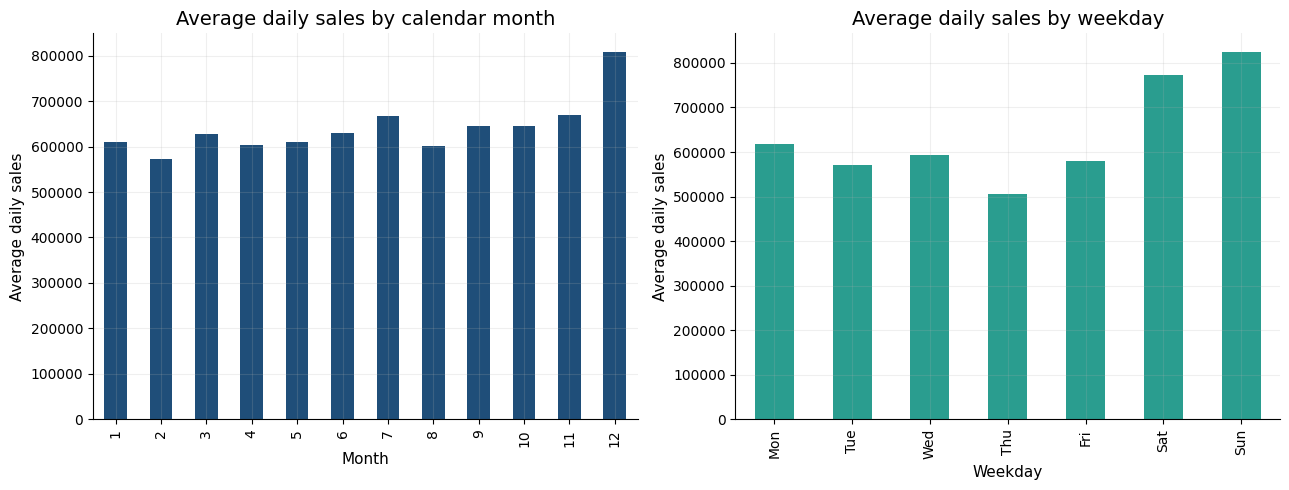

In [4]:
calendar_daily = daily_total.rename("sales").reset_index()
calendar_daily["year"] = calendar_daily["date"].dt.year
calendar_daily["month"] = calendar_daily["date"].dt.month
calendar_daily["day_of_week"] = calendar_daily["date"].dt.dayofweek

yearly = calendar_daily.groupby("year").agg(total_sales=("sales", "sum"), mean_daily_sales=("sales", "mean"), days=("date", "nunique"))
monthly = calendar_daily.groupby("month")["sales"].mean()
weekday = calendar_daily.groupby("day_of_week")["sales"].mean().reindex(range(7))
weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
display(yearly)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
monthly.plot(kind="bar", ax=axes[0], color=PROJECT_COLORS[0])
axes[0].set(title="Average daily sales by calendar month", xlabel="Month", ylabel="Average daily sales")
weekday.plot(kind="bar", ax=axes[1], color=PROJECT_COLORS[1])
axes[1].set(title="Average daily sales by weekday", xlabel="Weekday", ylabel="Average daily sales")
fig.tight_layout()
save_figure(fig, FIGURE_DIR, "eda_02_calendar_patterns.png")
plt.show()

### 3. Store ranking, type, cluster, and geography

**Why this step is needed:** Store totals alone do not explain operating context. Adding format, cluster, geography, traffic coverage, and variability supports more defensible comparisons.

,total_sales,mean_daily_sales,std_daily_sales,transaction_coverage_pct,total_transactions,cv,sales_per_transaction_proxy,city,state,type,cluster
store_nbr,,,,,,,,,,,
44,"62,087,553.250","36,869.093","14,704.525",99.584,"7,273,093.000",0.399,8.537,Quito,Pichincha,A,5
45,"54,498,010.417","32,362.239","13,689.660",99.584,"6,201,115.000",0.423,8.788,Quito,Pichincha,A,11
47,"50,948,310.061","30,254.341","12,523.215",99.584,"6,535,810.000",0.414,7.795,Quito,Pichincha,A,14
3,"50,481,910.185","29,977.381","11,324.234",99.525,"5,366,350.000",0.378,9.407,Quito,Pichincha,D,8
49,"43,420,095.784","25,783.905","11,904.520",99.584,"4,574,103.000",0.462,9.493,Quito,Pichincha,A,11
46,"41,896,062.122","24,878.897","11,084.245",99.584,"5,990,113.000",0.446,6.994,Quito,Pichincha,A,14
48,"35,933,130.274","21,337.963","10,317.645",99.584,"5,107,785.000",0.484,7.035,Quito,Pichincha,A,14
51,"32,911,489.538","19,543.640","6,439.521",99.584,"2,873,614.000",0.329,11.453,Guayaquil,Guayas,A,17
8,"30,494,286.928","18,108.246","6,757.231",99.525,"4,637,971.000",0.373,6.575,Quito,Pichincha,D,8


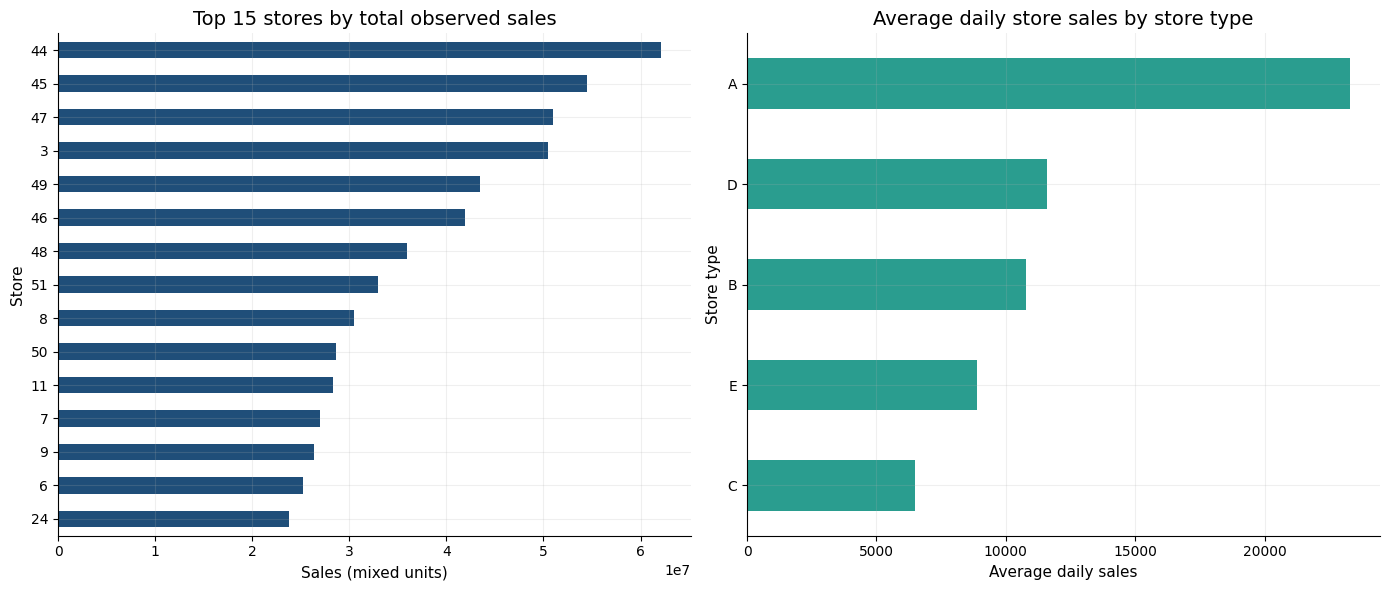

,stores,total_sales,mean_store_daily_sales
state,,,
Pichincha,19,"585,067,395.309","18,285.642"
Guayas,11,"165,154,392.382","8,915.698"
Azuay,3,"49,168,596.033","9,732.501"
Tungurahua,2,"40,304,401.300","11,966.865"
Santo Domingo de los Tsachilas,3,"35,834,323.037","7,093.096"
El Oro,2,"33,386,796.545","9,912.944"
Los Rios,2,"31,925,373.995","9,479.030"
Manabi,3,"24,969,820.134","4,942.561"
Cotopaxi,2,"21,182,263.775","6,289.271"


,stores,mean_store_daily_sales,mean_cv
cluster,,,
5,1,"36,869.093",0.399
14,4,"23,371.515",0.427
8,3,"21,363.469",0.369
11,3,"19,915.732",1.541
17,1,"19,543.640",0.329
6,6,"11,307.837",0.623
1,3,"10,763.411",0.510
12,1,"10,707.226",0.415
13,4,"10,704.016",0.527


In [5]:
store_daily = panel.groupby(["store_nbr", "date"], observed=True).agg(
    sales=("sales", "sum"), transactions=("transactions", "max")
).reset_index()
store_summary = store_daily.groupby("store_nbr").agg(
    total_sales=("sales", "sum"),
    mean_daily_sales=("sales", "mean"),
    std_daily_sales=("sales", "std"),
    transaction_coverage_pct=("transactions", lambda values: 100 * values.notna().mean()),
    total_transactions=("transactions", "sum"),
)
store_summary["cv"] = store_summary["std_daily_sales"] / store_summary["mean_daily_sales"]
store_summary["sales_per_transaction_proxy"] = store_summary["total_sales"] / store_summary["total_transactions"]
store_summary = store_summary.join(datasets["stores.csv"].set_index("store_nbr"))
display(store_summary.nlargest(10, "total_sales"))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
store_summary.nlargest(15, "total_sales").sort_values("total_sales")["total_sales"].plot(
    kind="barh", ax=axes[0], color=PROJECT_COLORS[0]
)
axes[0].set(title="Top 15 stores by total observed sales", xlabel="Sales (mixed units)", ylabel="Store")
store_summary.groupby("type", observed=True)["mean_daily_sales"].mean().sort_values().plot(
    kind="barh", ax=axes[1], color=PROJECT_COLORS[1]
)
axes[1].set(title="Average daily store sales by store type", xlabel="Average daily sales", ylabel="Store type")
fig.tight_layout()
save_figure(fig, FIGURE_DIR, "eda_03_store_performance.png")
plt.show()

geo_summary = store_summary.groupby("state", observed=True).agg(
    stores=("total_sales", "size"), total_sales=("total_sales", "sum"), mean_store_daily_sales=("mean_daily_sales", "mean")
).sort_values("total_sales", ascending=False)
cluster_summary = store_summary.groupby("cluster", observed=True).agg(
    stores=("total_sales", "size"), mean_store_daily_sales=("mean_daily_sales", "mean"), mean_cv=("cv", "mean")
).sort_values("mean_store_daily_sales", ascending=False)
display(geo_summary.head(10))
display(cluster_summary)

### 4. Product-family importance, variability, and growth

**Why this step is needed:** Volume indicates commercial importance, whereas variability indicates planning difficulty. Both are needed to avoid treating high-sales and high-uncertainty categories as the same problem.

,total_sales,mean_daily_sales,std_daily_sales,cv,sales_share_pct,growth_first_to_last_full_year_pct
family,,,,,,
GROCERY I,"343,462,734.886","203,956.493","61,832.885",0.303,31.990,47.560
BEVERAGES,"216,954,486.000","128,832.830","63,121.646",0.490,20.207,183.534
PRODUCE,"122,704,684.676","72,865.015","61,847.253",0.849,11.429,"60,676.184"
CLEANING,"97,521,289.000","57,910.504","15,211.881",0.263,9.083,29.201
DAIRY,"64,487,709.000","38,294.364","13,725.805",0.358,6.006,119.246
BREAD/BAKERY,"42,133,945.576","25,020.158","6,511.796",0.260,3.924,46.630
POULTRY,"31,876,004.472","18,928.744","6,078.422",0.321,2.969,71.070
MEATS,"31,086,468.404","18,459.898","4,334.043",0.235,2.895,8.474
PERSONAL CARE,"24,592,051.000","14,603.356","5,361.252",0.367,2.291,61.553


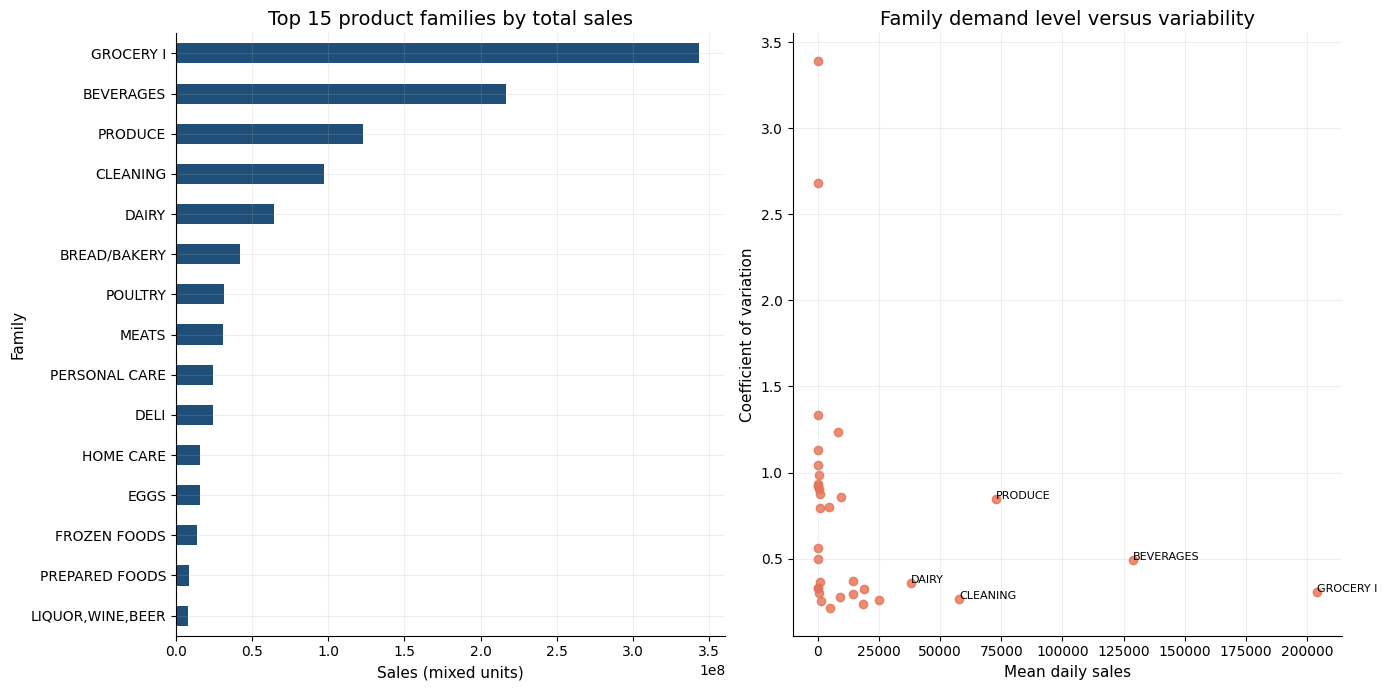

In [6]:
family_daily = panel.groupby(["family", "date"], observed=True)["sales"].sum().reset_index()
family_summary = family_daily.groupby("family", observed=True)["sales"].agg(
    total_sales="sum", mean_daily_sales="mean", std_daily_sales="std"
)
family_summary["cv"] = family_summary["std_daily_sales"] / family_summary["mean_daily_sales"]
family_summary["sales_share_pct"] = 100 * family_summary["total_sales"] / family_summary["total_sales"].sum()

first_year = panel["year"].min()
last_full_year = panel.loc[panel["year"].lt(panel["year"].max()), "year"].max()
family_year = panel.groupby(["family", "year"], observed=True)["sales"].sum().unstack(fill_value=0)
family_summary["growth_first_to_last_full_year_pct"] = 100 * (
    family_year[last_full_year] / family_year[first_year].replace(0, np.nan) - 1
)
display(family_summary.sort_values("total_sales", ascending=False).head(15))

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
family_summary.nlargest(15, "total_sales").sort_values("total_sales")["total_sales"].plot(
    kind="barh", ax=axes[0], color=PROJECT_COLORS[0]
)
axes[0].set(title="Top 15 product families by total sales", xlabel="Sales (mixed units)", ylabel="Family")
axes[1].scatter(family_summary["mean_daily_sales"], family_summary["cv"], color=PROJECT_COLORS[4], alpha=.8)
for family in family_summary.nlargest(5, "total_sales").index:
    axes[1].annotate(family, (family_summary.loc[family, "mean_daily_sales"], family_summary.loc[family, "cv"]), fontsize=8)
axes[1].set(title="Family demand level versus variability", xlabel="Mean daily sales", ylabel="Coefficient of variation")
fig.tight_layout()
save_figure(fig, FIGURE_DIR, "eda_04_family_importance_variability.png")
plt.show()

### 5. Detailed store-family comparison for the justified subset

**Why this step is needed:** A store-family view reveals differences hidden by network totals and creates a manageable visual for an MBA presentation.

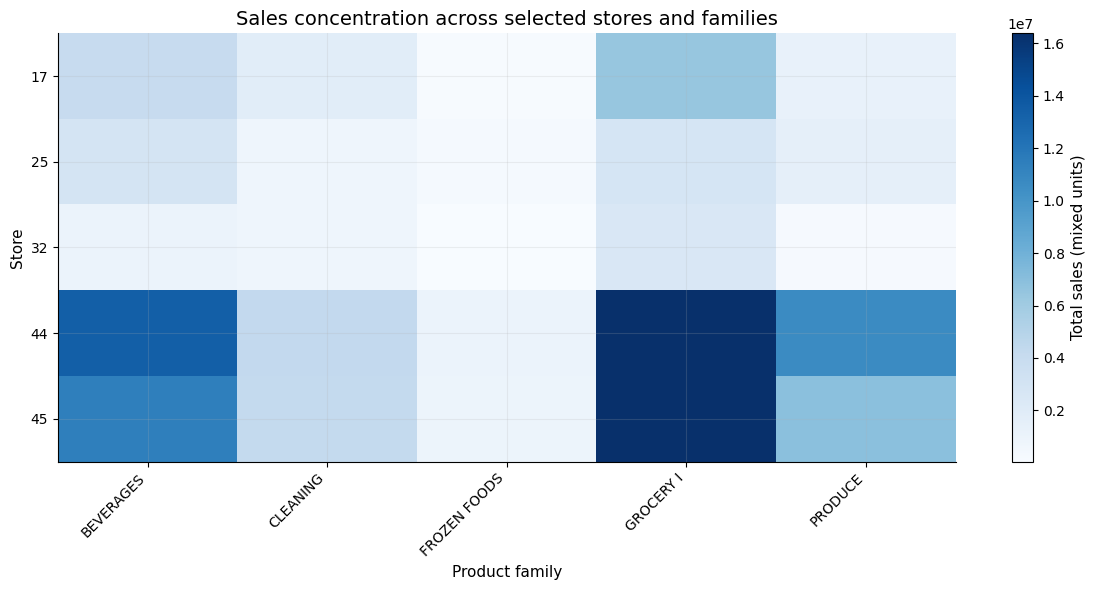

In [7]:
scope_panel = panel.loc[
    panel["store_nbr"].isin(selected_stores) & panel["family"].isin(selected_families)
]
store_family = scope_panel.groupby(["store_nbr", "family"], observed=True)["sales"].sum().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(12, 6))
image = ax.imshow(store_family, aspect="auto", cmap="Blues")
ax.set_xticks(range(len(store_family.columns)), labels=store_family.columns, rotation=45, ha="right")
ax.set_yticks(range(len(store_family.index)), labels=store_family.index)
ax.set(title="Sales concentration across selected stores and families", xlabel="Product family", ylabel="Store")
fig.colorbar(image, ax=ax, label="Total sales (mixed units)")
fig.tight_layout()
save_figure(fig, FIGURE_DIR, "eda_05_store_family_heatmap.png")
plt.show()

### 6. Promotion association and heterogeneity

**Why this step is needed:** Comparing promoted and non-promoted observations identifies where operational coordination may matter, while remaining explicitly descriptive because promotions were not randomly assigned.

,mean_sales_not_promoted,mean_sales_promoted,promoted_to_nonpromoted_ratio,promotion_coverage_pct
family,,,,
SCHOOL AND OFFICE SUPPLIES,1.022,44.529,43.570,4.458
BABY CARE,0.110,1.660,15.146,0.058
PET SUPPLIES,3.507,15.835,4.515,3.357
HOME AND KITCHEN II,10.275,41.158,4.006,20.876
PRODUCE,792.102,"2,438.220",3.078,33.852
HOME APPLIANCES,0.457,1.397,3.057,0.064
LAWN AND GARDEN,5.511,16.787,3.046,4.654
HOME CARE,101.956,309.445,3.035,35.781
PLAYERS AND ELECTRONICS,6.082,17.364,2.855,0.934


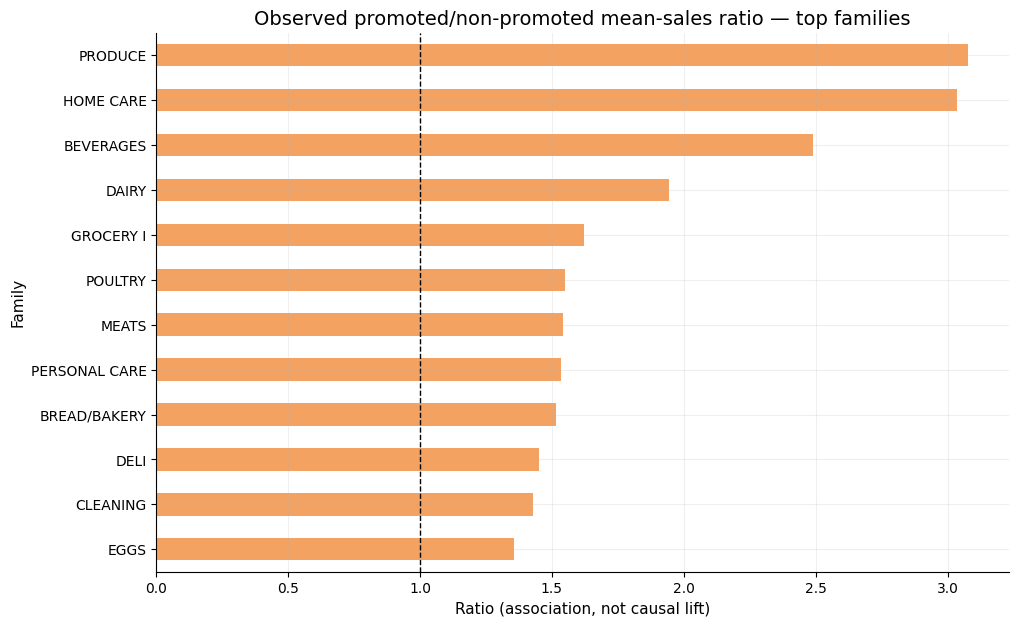

store_nbr
52   319.704
22    37.077
21    34.553
42    30.951
29    30.394
20    27.471
53    16.912
35     9.173
36     8.836
40     8.802
Name: promoted_to_nonpromoted_ratio, dtype: float64

In [8]:
promotion_comparison = panel.assign(promoted=panel["onpromotion"].gt(0)).groupby(
    ["family", "promoted"], observed=True
)["sales"].mean().unstack()
promotion_comparison.columns = ["mean_sales_not_promoted", "mean_sales_promoted"]
promotion_comparison["promoted_to_nonpromoted_ratio"] = (
    promotion_comparison["mean_sales_promoted"] / promotion_comparison["mean_sales_not_promoted"].replace(0, np.nan)
)
promotion_comparison["promotion_coverage_pct"] = panel.groupby("family", observed=True)["onpromotion"].apply(
    lambda values: 100 * values.gt(0).mean()
)
display(promotion_comparison.sort_values("promoted_to_nonpromoted_ratio", ascending=False).head(15))

plot_promo = promotion_comparison.loc[family_summary.nlargest(12, "total_sales").index].sort_values("promoted_to_nonpromoted_ratio")
fig, ax = plt.subplots(figsize=(11, 7))
plot_promo["promoted_to_nonpromoted_ratio"].plot(kind="barh", ax=ax, color=PROJECT_COLORS[3])
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.set(title="Observed promoted/non-promoted mean-sales ratio — top families", xlabel="Ratio (association, not causal lift)", ylabel="Family")
save_figure(fig, FIGURE_DIR, "eda_06_promotion_association.png")
plt.show()

store_promo = panel.assign(promoted=panel["onpromotion"].gt(0)).groupby(
    ["store_nbr", "promoted"], observed=True
)["sales"].mean().unstack()
store_promo["ratio"] = store_promo[True] / store_promo[False].replace(0, np.nan)
display(store_promo["ratio"].sort_values(ascending=False).head(10).rename("promoted_to_nonpromoted_ratio"))

### 7. Holidays and major events

**Why this step is needed:** Holiday effects can differ by national, regional, and local scope. Scope-aware comparisons help identify potential peak periods without misapplying local events to every store.

In [9]:
store_date = panel.groupby(["store_nbr", "date"], observed=True).agg(
    sales=("sales", "sum"),
    is_holiday=("is_holiday", "max"),
    is_national_holiday=("is_national_holiday", "max"),
    is_regional_holiday=("is_regional_holiday", "max"),
    is_local_holiday=("is_local_holiday", "max"),
).reset_index()
holiday_comparison = store_date.groupby("is_holiday")["sales"].agg(["count", "mean", "median", "std"])
display(holiday_comparison)

scope_means = {}
for column in ("is_national_holiday", "is_regional_holiday", "is_local_holiday"):
    scope_means[column] = store_date.groupby(column)["sales"].mean().to_dict()
display(pd.DataFrame(scope_means).T.rename(columns={False: "normal_or_other", True: "flagged_scope"}))

daily_event = datasets["holidays_events.csv"].loc[
    ~datasets["holidays_events.csv"]["transferred"]
].groupby("date")["description"].agg(lambda values: " | ".join(sorted(set(values))))
daily_sales = daily_total.to_frame().join(daily_event).dropna()
display(daily_sales.nlargest(12, "sales"))

,count,mean,median,std
is_holiday,,,,
False,83216,"11,618.297","9,210.159","9,695.232"
True,7720,"13,836.362","10,744.194","11,947.057"


,normal_or_other,flagged_scope
is_national_holiday,"11,628.113","13,838.197"
is_regional_holiday,"11,808.041","7,580.940"
is_local_holiday,"11,797.505","14,094.797"


,sales,description
date,,
2017-04-01,"1,463,083.962",Provincializacion de Cotopaxi
2017-01-02,"1,402,306.371",Traslado Primer dia del ano
2016-04-18,"1,345,920.605",Terremoto Manabi+2
2017-05-01,"1,306,699.367",Dia del Trabajo
2016-12-23,"1,282,145.517",Navidad-2
2016-04-17,"1,271,833.739",Terremoto Manabi+1
2016-05-01,"1,270,121.208",Dia del Trabajo | Terremoto Manabi+15
2016-12-24,"1,246,837.843",Navidad-1
2015-12-23,"1,196,146.056",Navidad-2


### 8. Transactions, traffic, and the sales-per-transaction proxy

**Why this step is needed:** Transactions provide a store-traffic proxy that helps separate changes in customer visits from changes in the mixed-unit sales measure.

Store-day Pearson correlation between sales and transactions: 0.837


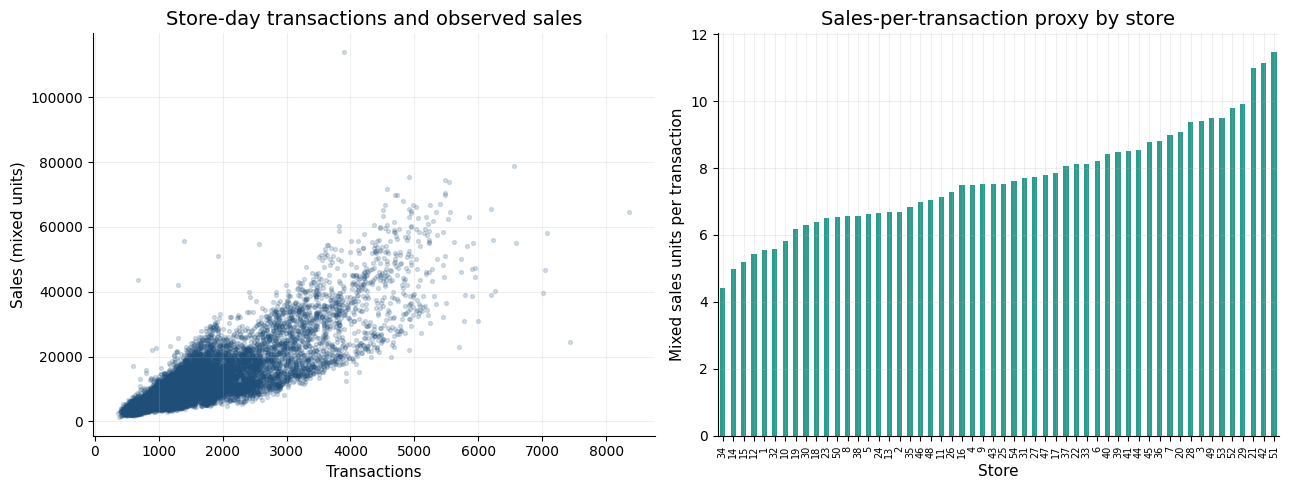

In [10]:
traffic = panel.groupby(["date", "store_nbr"], observed=True).agg(
    sales=("sales", "sum"), transactions=("transactions", "max")
).dropna().reset_index()
traffic["sales_per_transaction_proxy"] = traffic["sales"] / traffic["transactions"].replace(0, np.nan)
traffic_correlation = traffic[["sales", "transactions"]].corr().iloc[0, 1]
print(f"Store-day Pearson correlation between sales and transactions: {traffic_correlation:.3f}")

sample = traffic.sample(min(12000, len(traffic)), random_state=RANDOM_SEED)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(sample["transactions"], sample["sales"], s=8, alpha=.18, color=PROJECT_COLORS[0])
axes[0].set(title="Store-day transactions and observed sales", xlabel="Transactions", ylabel="Sales (mixed units)")
store_summary.sort_values("sales_per_transaction_proxy")["sales_per_transaction_proxy"].plot(
    kind="bar", ax=axes[1], color=PROJECT_COLORS[1]
)
axes[1].set(title="Sales-per-transaction proxy by store", xlabel="Store", ylabel="Mixed sales units per transaction")
axes[1].tick_params(axis="x", labelsize=7)
fig.tight_layout()
save_figure(fig, FIGURE_DIR, "eda_07_transactions.png")
plt.show()

### 9. Oil prices as exploratory context

**Why this step is needed:** Oil is a possible macroeconomic context variable, but a visual and correlation are used only to screen for patterns—not to claim that oil prices cause demand changes.

Monthly contemporaneous correlation: -0.788 (descriptive only)


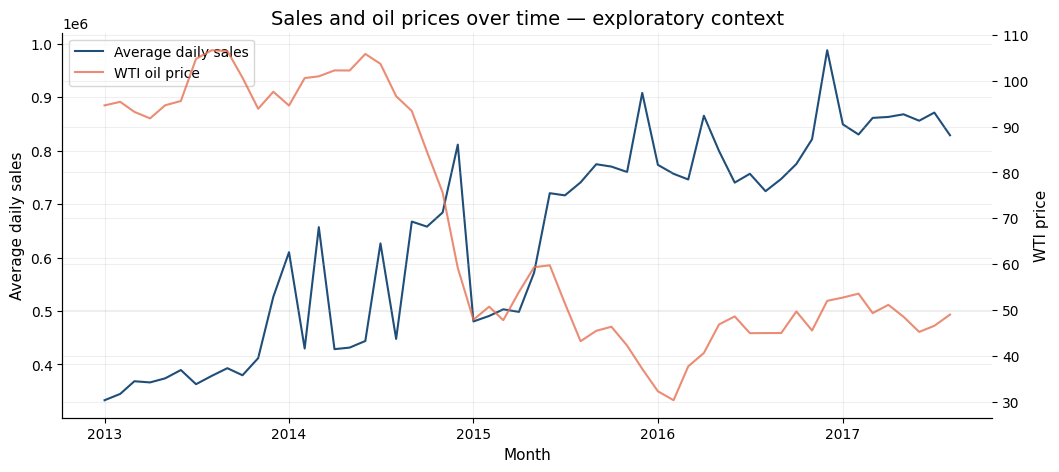

In [11]:
oil_daily = panel.groupby("date", observed=True).agg(
    sales=("sales", "sum"), dcoilwtico=("dcoilwtico", "max")
).reset_index()
oil_monthly = oil_daily.set_index("date").resample("MS").mean()
oil_corr = oil_monthly[["sales", "dcoilwtico"]].corr().iloc[0, 1]
print(f"Monthly contemporaneous correlation: {oil_corr:.3f} (descriptive only)")

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(oil_monthly.index, oil_monthly["sales"], color=PROJECT_COLORS[0], label="Average daily sales")
ax1.set(xlabel="Month", ylabel="Average daily sales")
ax2 = ax1.twinx()
ax2.plot(oil_monthly.index, oil_monthly["dcoilwtico"], color=PROJECT_COLORS[4], label="WTI oil price", alpha=.8)
ax2.set_ylabel("WTI price")
ax1.set_title("Sales and oil prices over time — exploratory context")
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [line.get_label() for line in lines], loc="upper left")
save_figure(fig, FIGURE_DIR, "eda_08_oil_context.png")
plt.show()

### 10. Demand pattern classification (Syntetos-Boylan / Croston)

**Why this step is needed:** Retail demand varies not only by volume but by regularity. Each store–family series is classified separately so that pooling stores does not create an artificial time sequence. The four quadrants are screening indicators for forecasting and review cadence, not inventory-policy prescriptions.

,store_nbr,family,total_periods,active_periods,zero_sales_pct,adi,cv2,demand_category
44,2,FROZEN FOODS,1684,1679,0.300,1.003,1.248,Erratic
77,3,FROZEN FOODS,1684,1679,0.300,1.003,0.990,Erratic
110,4,FROZEN FOODS,1684,1679,0.300,1.003,2.076,Erratic
143,5,FROZEN FOODS,1684,1679,0.300,1.003,3.709,Erratic
176,6,FROZEN FOODS,1684,1679,0.300,1.003,1.228,Erratic
...,...,...,...,...,...,...,...,...
278,9,HARDWARE,1684,1307,22.390,1.288,0.475,Smooth
464,15,BEAUTY,1684,1303,22.620,1.292,0.435,Smooth
212,7,HARDWARE,1684,1290,23.400,1.305,0.480,Smooth
1268,39,HARDWARE,1684,1282,23.870,1.314,0.484,Smooth


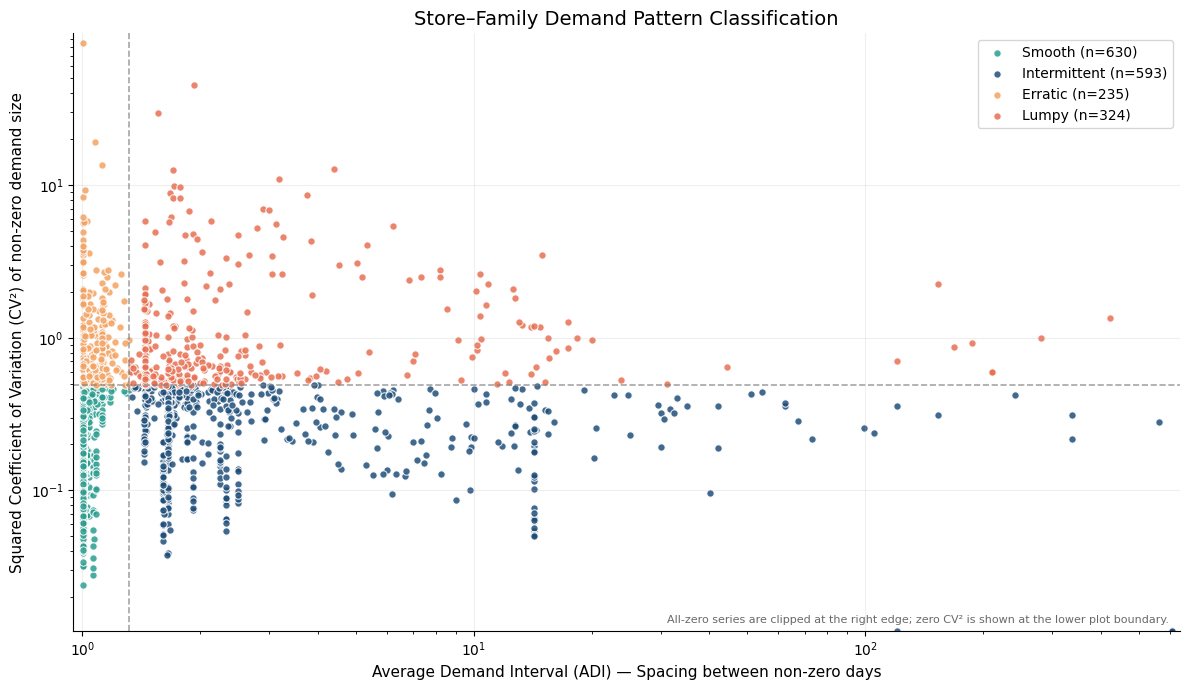

In [12]:
demand_classification = classify_demand_patterns(panel, group_cols=["store_nbr", "family"])
display(demand_classification.sort_values(["demand_category", "adi"]))
fig = plot_demand_classification(demand_classification, output_dir=FIGURE_DIR)
plt.show()

### 11. Semi-monthly payday dynamics (Quincenas: 15th & month-end)

**Why this step is needed:** The competition context identifies the 15th and month-end as potentially relevant pay-cycle dates. This descriptive comparison uses the 15th/month-end plus the following day as a semi-month boundary proxy. It does not control for weekday, holidays, trend, or promotion mix and therefore is not a causal payday effect.

,days,mean_daily_sales,median_daily_sales,std_daily_sales,lift_pct
is_payday,,,,,
False,1462,"633,781.886","625,963.979","231,434.896",4.520
True,222,"662,413.671","670,287.763","252,279.326",4.520


,regular_day_sales,payday_sales,payday_lift_pct
family,,,
BABY CARE,0.108,0.125,15.340
PERSONAL CARE,267.032,292.829,9.660
BEAUTY,3.683,3.933,6.810
CLEANING,"1,063.440","1,131.534",6.400
HOME CARE,174.762,185.654,6.230
DELI,262.975,279.361,6.230
GROCERY I,"3,748.265","3,966.024",5.810
"LIQUOR,WINE,BEER",84.551,89.383,5.720
POULTRY,348.328,365.047,4.800


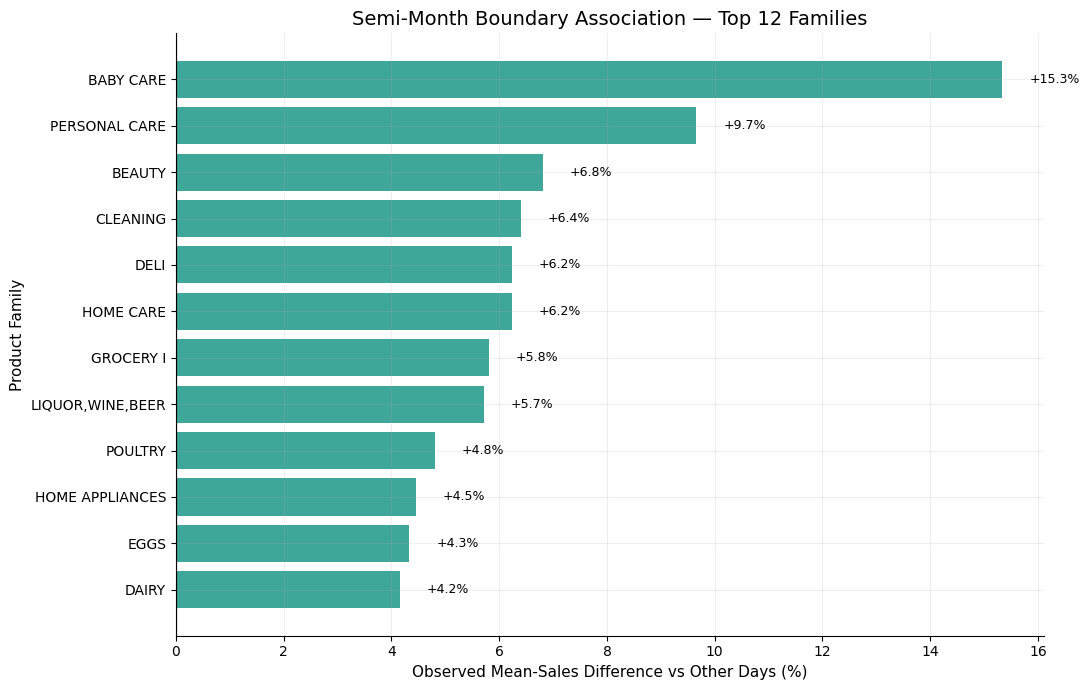

In [13]:
payday_results = analyze_payday_effects(panel)
display(payday_results["summary"])
display(payday_results["by_family"].head(10))
fig = plot_payday_comparison(payday_results["by_family"], top_n=12, output_dir=FIGURE_DIR)
plt.show()

### 12. Structural shock analysis: April 16, 2016 earthquake

**Why this step is needed:** The dataset period includes the April 16, 2016 Ecuador earthquake. Equal 30-day pre/post windows are compared using average daily sales by province and family. Changes are temporally associated with the event but can also reflect trend, seasonality, promotions, closures, or relief activity.

period,post_quake,pre_quake,total_change_pct
state,,,
Manabi,"24,939.244","15,123.093",64.910
Guayas,"141,720.124","113,444.525",24.920
Santo Domingo de los Tsachilas,"30,623.633","25,536.691",19.920
Pichincha,"486,994.757","412,922.667",17.940
Los Rios,"24,010.983","20,827.129",15.290
Cotopaxi,"16,419.573","14,292.363",14.880
Chimborazo,"8,401.667","7,331.835",14.590
Imbabura,"8,841.469","7,803.131",13.310
Azuay,"43,151.251","38,220.868",12.900


period,post_quake,pre_quake,sales_change_pct
family,,,
SCHOOL AND OFFICE SUPPLIES,480.467,129.767,270.250
HOME APPLIANCES,30.033,8.500,253.330
MAGAZINES,436.700,262.367,66.450
LINGERIE,366.533,252.600,45.100
BABY CARE,14.367,10.200,40.850
PLAYERS AND ELECTRONICS,634.067,468.667,35.290
PERSONAL CARE,"21,259.000","15,837.033",34.240
GROCERY I,"288,970.179","219,655.970",31.560
HOME CARE,"18,220.800","14,553.167",25.200


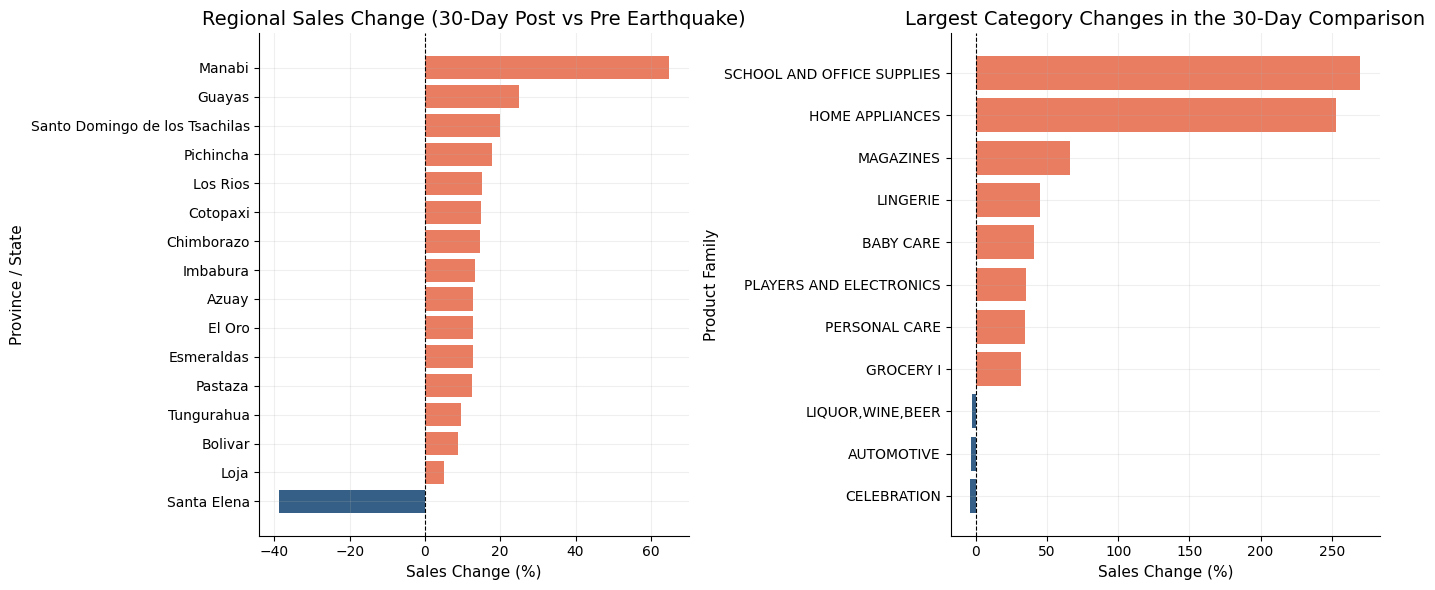

In [14]:
quake_results = analyze_earthquake_impact(panel, window_days=30)
display(quake_results["regional_impact"].head(10))
display(quake_results["family_shift"].head(10))
fig = plot_earthquake_impact(quake_results, output_dir=FIGURE_DIR)
plt.show()

### 13. Cross-category demand correlation & co-movement

**Why this step is needed:** Correlations use daily log-sales changes after removing each date's cross-family mean change. This reduces shared trends and common network movement so the heatmap emphasizes relative category co-movement. Correlation still does not establish complementarity, substitution, or causation.

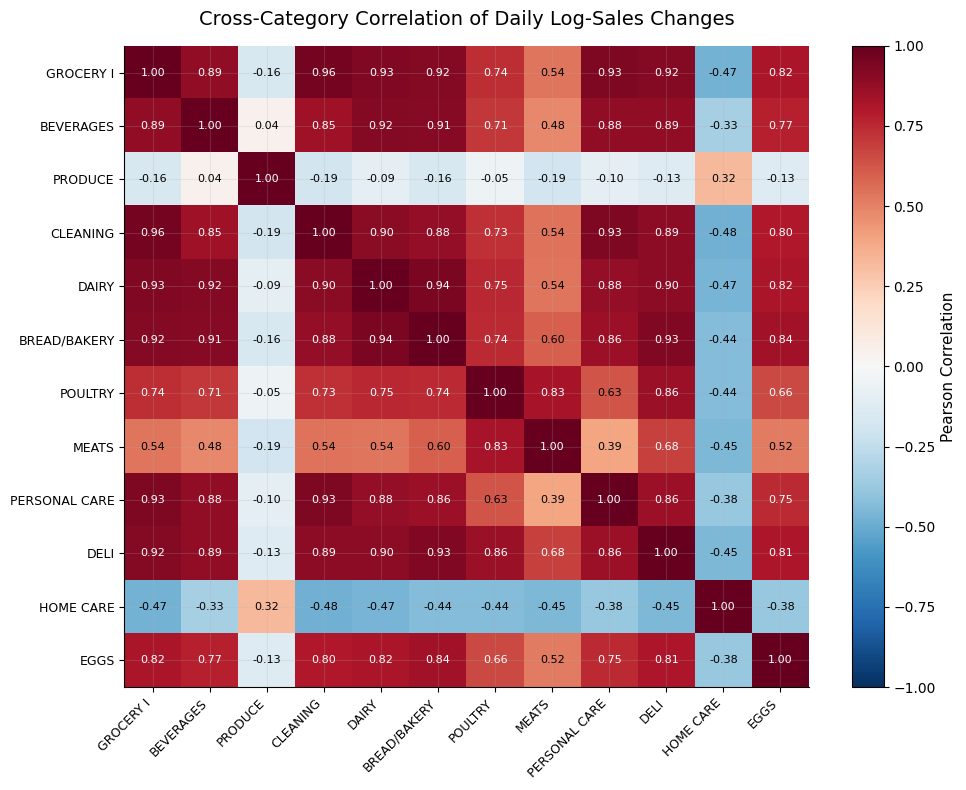

In [15]:
corr_matrix = compute_cross_family_correlations(panel)
top_volume_families = list(family_summary.nlargest(12, "total_sales").index)
fig = plot_correlation_heatmap(corr_matrix, top_families=top_volume_families, output_dir=FIGURE_DIR)
plt.show()

### 14. Save compact evidence tables

**Why this step is needed:** Persisting reviewed summaries lets operations, forecasting, and managerial notebooks reuse the same evidence rather than recomputing or manually copying values.

In [16]:
store_summary.reset_index().to_csv(TABLE_DIR / "store_summary.csv", index=False)
family_summary.reset_index().to_csv(TABLE_DIR / "family_summary.csv", index=False)
promotion_comparison.reset_index().to_csv(TABLE_DIR / "promotion_summary.csv", index=False)
yearly.reset_index().to_csv(TABLE_DIR / "yearly_summary.csv", index=False)
holiday_comparison.reset_index().to_csv(TABLE_DIR / "holiday_summary.csv", index=False)
demand_classification.to_csv(TABLE_DIR / "demand_classification_summary.csv", index=False)
demand_classification["demand_category"].value_counts().rename_axis("demand_category").reset_index(name="series_count").to_csv(
    TABLE_DIR / "demand_classification_counts.csv", index=False
)
payday_results["summary"].reset_index().to_csv(TABLE_DIR / "payday_overall_summary.csv", index=False)
payday_results["by_family"].reset_index().to_csv(TABLE_DIR / "payday_summary.csv", index=False)
quake_results["regional_impact"].reset_index().to_csv(TABLE_DIR / "earthquake_regional_impact.csv", index=False)
quake_results["family_shift"].reset_index().to_csv(TABLE_DIR / "earthquake_family_impact.csv", index=False)
corr_matrix.reset_index().to_csv(TABLE_DIR / "cross_family_correlations.csv", index=False)
print("Saved twelve compact evidence tables to reports/tables/.")

Saved twelve compact evidence tables to reports/tables/.


## Takeaways

In [17]:
top_store = store_summary["total_sales"].idxmax()
top_family = family_summary["total_sales"].idxmax()
peak_weekday = weekday.idxmax()
peak_month = int(monthly.idxmax())
classification_counts = demand_classification["demand_category"].value_counts().to_dict()
payday_lift = payday_results["summary"].loc[True, "lift_pct"]
manabi_change = quake_results["regional_impact"].loc["Manabi", "total_change_pct"]
display(Markdown(f'''
- **Store {top_store}** has the highest total observed sales; store scale and variability differ materially across the network.
- **{top_family}** contributes the most family-level sales, while family CV shows that importance and predictability are separate operational dimensions.
- Average daily demand is highest on **{peak_weekday}** and in calendar month **{peak_month}**, which motivates differentiated staffing and replenishment review.
- Promoted rows often have higher mean sales, but the ratio varies by family and store and must be treated as association rather than incremental causal lift.
- Holiday effects vary by scope; date-only joins would obscure local and regional relevance.
- Transactions and sales move together (store-day correlation **{traffic_correlation:.3f}**), but the mixed-unit sales-per-transaction measure is only a basket proxy.
- The monthly sales/oil correlation is **{oil_corr:.3f}** and is exploratory; shared trends and omitted factors prevent causal interpretation.
- **Demand classification:** Store–family series counts are {classification_counts}. This supports differentiated forecast evaluation and review cadence; it does not specify safety stocks without inventory inputs.
- **Semi-month boundary association:** Average network sales are **{payday_lift:.2f}%** higher in the defined 15th/month-end window, before controlling for calendar or promotion mix.
- **Structural-shock window:** Manabí average daily sales are **{manabi_change:.2f}%** higher in the 30 days from April 16, 2016 than in the preceding 30 days. This is temporal association, not a causal estimate.
'''))


- **Store 44** has the highest total observed sales; store scale and variability differ materially across the network.
- **GROCERY I** contributes the most family-level sales, while family CV shows that importance and predictability are separate operational dimensions.
- Average daily demand is highest on **Sun** and in calendar month **12**, which motivates differentiated staffing and replenishment review.
- Promoted rows often have higher mean sales, but the ratio varies by family and store and must be treated as association rather than incremental causal lift.
- Holiday effects vary by scope; date-only joins would obscure local and regional relevance.
- Transactions and sales move together (store-day correlation **0.837**), but the mixed-unit sales-per-transaction measure is only a basket proxy.
- The monthly sales/oil correlation is **-0.788** and is exploratory; shared trends and omitted factors prevent causal interpretation.
- **Demand classification:** Store–family series counts are {'Smooth': 630, 'Intermittent': 593, 'Lumpy': 324, 'Erratic': 235}. This supports differentiated forecast evaluation and review cadence; it does not specify safety stocks without inventory inputs.
- **Semi-month boundary association:** Average network sales are **4.52%** higher in the defined 15th/month-end window, before controlling for calendar or promotion mix.
- **Structural-shock window:** Manabí average daily sales are **64.91%** higher in the 30 days from April 16, 2016 than in the preceding 30 days. This is temporal association, not a causal estimate.
